# Visual Search Engine: Image Embeddings + Similarity Search

**Stage 1 — Educational notebook**

In this project we will build a search engine that accepts an image instead of keywords. We will use a pretrained vision model, cosine similarity, and Top-K retrieval. We will not train a neural network.

Our pipeline is: **Dataset → Pretrained Model → Embeddings → Similarity → Top-K Images**.

## 01. Project introduction and problem definition

A normal product search may use words such as *black sneaker*. But what if a user has a picture and does not know the correct description? Visual search represents both the query and catalog images as numbers, compares those numbers, and returns the closest results.

## 02. Traditional keyword search vs visual search

| Keyword search | Visual search |
|---|---|
| Input is text | Input is an image |
| Matches words or text features | Matches learned visual features |
| Needs useful descriptions | Can work without a detailed description |
| Example: `red dress` | Example: upload a dress photo |

Visual search is not automatically perfect. Its quality depends on the pretrained model, its original training data, the new dataset, and image quality.

## 03. Imports and project settings

Keep the cells small and run them in order. `MAX_IMAGES=15000` uses the prepared advanced catalog subset. Change it to 2000 for a faster classroom experiment.

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics.pairwise import cosine_similarity
from torch.utils.data import DataLoader, Dataset
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small


In [2]:

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == 'notebooks':
    PROJECT_DIR = PROJECT_DIR.parent
sys.path.insert(0, str(PROJECT_DIR))

DATA_DIR = PROJECT_DIR / 'data'
IMAGES_DIR = DATA_DIR / 'images'
METADATA_PATH = DATA_DIR / 'metadata.csv'
EMBEDDINGS_PATH = DATA_DIR / 'embeddings.npy'
MAX_IMAGES = 15000
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print('Project folder:', PROJECT_DIR)
print('PyTorch version:', torch.__version__)

Project folder: PyTorch version: 2.13.0+cu130


## 04. Dataset

We use Fashion Product Images (Small), a public e-commerce catalog with more than 44,000 color product photographs and rich metadata. To keep the project laptop-friendly, we select a reproducible 15,000-image subset balanced across Apparel, Accessories, Footwear, and Personal Care.

The preparation script downloads the source files, exports normal RGB PNG files, and creates one metadata row per image. Category labels are used for evaluation—not for generating the embeddings.

In [3]:
from prepare_dataset import prepare_dataset

prepare_dataset(max_images=MAX_IMAGES)

Copying 15,000 selected product images...


  Copied 1,000 images


  Copied 2,000 images


  Copied 3,000 images


  Copied 4,000 images


...

  Copied 11,000 images


  Copied 12,000 images


  Copied 13,000 images


  Copied 14,000 images


  Copied 15,000 images
Saved metadata to: data\metadata.csv

Master-category distribution:
master_category
Footwear         4500
Accessories      4500
Apparel          4500
Personal Care    1500
Name: count, dtype: int64

Search/evaluation categories:
category
Shoes                       3565
Topwear                     3253
Bags                        1229
Watches                     1074
Fragrance                    640
Bottomwear                   570
Sandal                       477
Flip Flops                   458
Eyewear                      440
Jewellery                    428
Innerwear                    382
Wallets                      351
Lips                         330
Belts                        302
Socks                        277
Nails                        202
Makeup                       196
Headwear                     111
Saree                         96
Dress                         96
Ties                          94
Loungewear and Nightwear      79
Accessories  

**Interpretation:** The PNG files are our image collection. `metadata.csv` connects each image path to its ID and category so we can display and evaluate results later.

## 05. Explore the metadata

Before using a model, always check the table size, columns, missing values, and category distribution.

In [4]:
metadata = pd.read_csv(METADATA_PATH)
print('Rows and columns:', metadata.shape)
display(metadata.head())
display(metadata.isna().sum().rename('missing_values'))

Rows and columns: (15000, 13)


,image_id,image_path,category,category_id,master_category,subcategory,article_type,color,gender,season,usage,product_name,split
0,11925,data/images/11925.jpg,Shoes,28,Footwear,Shoes,Flats,Black,Women,Winter,Casual,Skechers Women Tone Black Sandals,catalog
1,52836,data/images/52836.jpg,Jewellery,17,Accessories,Jewellery,Earrings,Red,Women,Fall,Casual,Adrika Women Red & Gold Earrings,catalog
2,30252,data/images/30252.jpg,Shoes,28,Footwear,Shoes,Casual Shoes,Black,Men,Summer,Casual,Numero Uno Men Black Shoes,catalog
3,57812,data/images/57812.jpg,Dress,8,Apparel,Dress,Jumpsuit,Brown,Women,Summer,Casual,United Colors of Benetton Women Brown Jumpsuit,catalog
4,17386,data/images/17386.jpg,Mufflers,21,Accessories,Mufflers,Mufflers,Black,Men,Fall,Casual,Reid & Taylor Men Solid Black Muffler,catalog


image_id           0
image_path         0
category           0
category_id        0
master_category    0
subcategory        0
article_type       0
color              0
gender             0
season             0
usage              0
product_name       0
split              0
Name: missing_values, dtype: int64

category
Accessories                   51
Apparel Set                   21
Bags                        1229
Bath and Body                  8
Beauty Accessories             3
Belts                        302
Bottomwear                   570
Cufflinks                     35
Dress                         96
Eyes                          19
Eyewear                      440
Flip Flops                   458
Fragrance                    640
Gloves                         9
Hair                           9
Headwear                     111
Innerwear                    382
Jewellery                    428
Lips                         330
Loungewear and Nightwear      79
Makeup                       196
Mufflers                      17
Nails                        202
Perfumes                       3
Sandal                       477
Saree                         96
Scarves                       38
Shoe Accessories              10
Shoes                       3565
Skin                          45
S

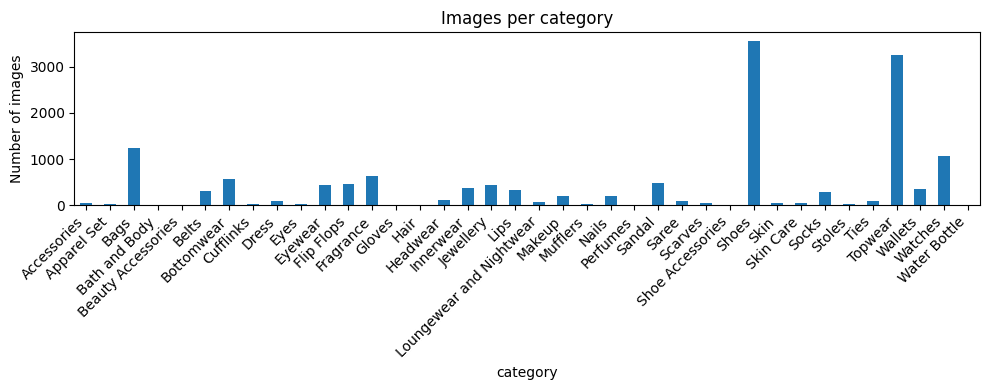

In [5]:
category_counts = metadata['category'].value_counts().sort_index()
display(category_counts)
category_counts.plot(kind='bar', figsize=(10, 4), title='Images per category')
plt.ylabel('Number of images')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Interpretation:** A balanced dataset makes category-based evaluation easier to interpret because no single category dominates the collection.

## 06. Display sample images

Looking at real examples helps us understand the dataset's resolution, style, and limitations before trusting any metric.

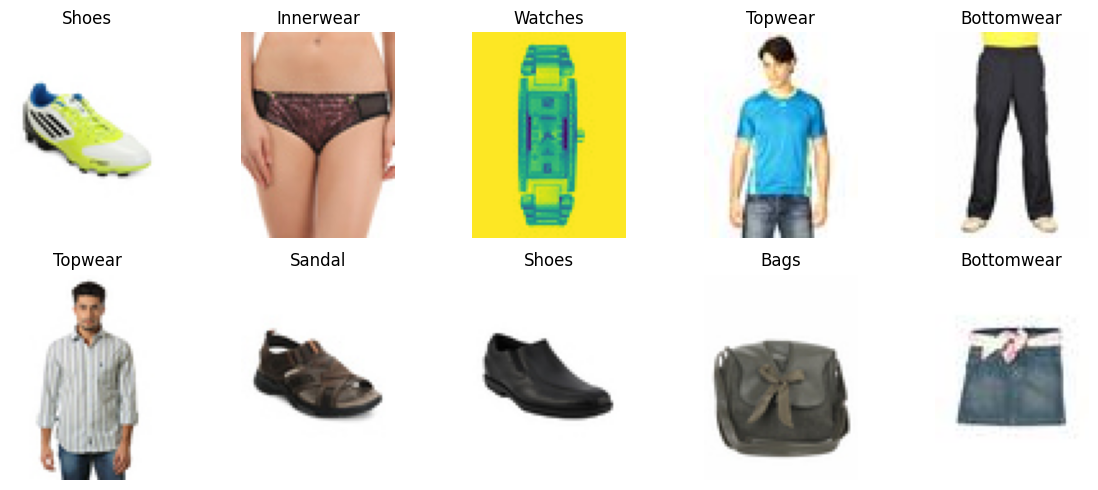

In [6]:
sample_rows = metadata.sample(10, random_state=RANDOM_SEED)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for axis, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    image = Image.open(PROJECT_DIR / row['image_path'])
    axis.imshow(image)
    axis.set_title(row['category'])
    axis.axis('off')

plt.tight_layout()
plt.show()

**Interpretation:** These are real color catalog photographs with varied product types, shapes, and colors. Clean product backgrounds make them well suited to visual similarity search.

## 07. Load a pretrained vision model

MobileNetV3-Small already learned useful visual patterns from ImageNet. Its normal classifier produces 1,000 class scores. We replace only that classifier with `Identity`, so the network returns the 576 learned features before classification. We keep all learned weights and do not train anything.

In [7]:
weights = MobileNet_V3_Small_Weights.DEFAULT
model = mobilenet_v3_small(weights=weights)
model.classifier = torch.nn.Identity()
model.eval()
preprocessing = weights.transforms()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)
print('Device:', device)
print('The classifier is now:', model.classifier)

Device: cuda
The classifier is now: Identity()


## 08. What is an image embedding?

An image begins as a grid of pixel values. A pretrained model transforms those pixels through learned layers into a compact numerical vector:

`Image → Pretrained model → [0.12, -0.31, 0.87, ...] → Embedding`

Images that activate similar learned features often have closer embeddings. This often captures appearance and sometimes meaning, but it does **not** guarantee perfect semantic similarity.

## 09. Generate one embedding — keep the steps visible

First we perform each step directly. We will create helper functions only after understanding this flow.

In [8]:
one_row = metadata.iloc[0]
one_image = Image.open(PROJECT_DIR / one_row['image_path']).convert('RGB')
one_tensor = preprocessing(one_image)
batch_tensor = one_tensor.unsqueeze(0).to(device)

print('Original image size:', one_image.size)
print('After preprocessing:', one_tensor.shape)
print('After adding batch dimension:', batch_tensor.shape)

Original image size: (60, 80)
After preprocessing: torch.Size([3, 224, 224])
After adding batch dimension: torch.Size([1, 3, 224, 224])


In [9]:
with torch.no_grad():
    one_embedding_tensor = model(batch_tensor)

one_embedding = one_embedding_tensor.cpu().numpy()[0]
print('Embedding shape:', one_embedding.shape)
print('First 12 numbers:', np.round(one_embedding[:12], 3))

Embedding shape: (576,)
First 12 numbers: [ 0.048  0.11   0.225  0.03  -0.136 -0.243  0.559  0.263  0.246 -0.057
 -0.114  0.621]


**Interpretation:** The model converted one 224×224×3 preprocessed image into 576 feature values. The embedding is not a class label; it is a location in a learned feature space. `torch.no_grad()` is used because inference does not need training gradients.

## 10. Generate embeddings for the complete dataset

Doing one image at a time is easy to understand but slow. A `DataLoader` groups images into small batches. Batching changes efficiency, not the embedding concept: every output row still belongs to the metadata row at the same position.

In [10]:
class NotebookImageDataset(Dataset):
    def __init__(self, table, transform):
        self.table = table
        self.transform = transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        image_path = PROJECT_DIR / self.table.iloc[index]['image_path']
        with Image.open(image_path) as image:
            return self.transform(image.convert('RGB'))

image_dataset = NotebookImageDataset(metadata, preprocessing)
data_loader = DataLoader(image_dataset, batch_size=64, shuffle=False, num_workers=0)
print('Number of batches:', len(data_loader))

Number of batches: 235


In [11]:
embedding_batches = []
start_time = time.time()

for batch_number, image_batch in enumerate(data_loader, start=1):
    image_batch = image_batch.to(device)
    with torch.no_grad():
        batch_embeddings = model(image_batch)
        batch_embeddings = torch.nn.functional.normalize(batch_embeddings, p=2, dim=1)

    embedding_batches.append(batch_embeddings.cpu().numpy().astype('float32'))

    if batch_number % 20 == 0 or batch_number == len(data_loader):
        processed = min(batch_number * 64, len(metadata))
        print(f'Processed {processed:,} / {len(metadata):,}')

embeddings = np.vstack(embedding_batches)
elapsed_minutes = (time.time() - start_time) / 60
print('Final embedding matrix:', embeddings.shape)
print(f'Time: {elapsed_minutes:.1f} minutes')

Processed 1,280 / 15,000


Processed 2,560 / 15,000


Processed 3,840 / 15,000


Processed 5,120 / 15,000


Processed 6,400 / 15,000


...

Processed 10,240 / 15,000


Processed 11,520 / 15,000


Processed 12,800 / 15,000


Processed 14,080 / 15,000


Processed 15,000 / 15,000
Final embedding matrix: (15000, 576)
Time: 0.7 minutes


**Interpretation:** The embedding matrix has one row per image and 576 columns. `shuffle=False` is essential: row 0 of the matrix must still match row 0 of metadata. Each row was normalized to length 1 so later cosine similarity is simple.

## 11. Save and reload embeddings

Model inference is the slow step. We run it once and save the numerical matrix. The Streamlit app will load this file rather than regenerate 15,000 vectors for every upload.

In [12]:
np.save(EMBEDDINGS_PATH, embeddings)
print('Saved:', EMBEDDINGS_PATH)
print(f'File size: {EMBEDDINGS_PATH.stat().st_size / 1_000_000:.1f} MB')

Saved: data\embeddings.npy
File size: 34.6 MB


In [13]:
loaded_embeddings = np.load(EMBEDDINGS_PATH)
loaded_metadata = pd.read_csv(METADATA_PATH)

assert len(loaded_embeddings) == len(loaded_metadata)
assert loaded_embeddings.shape[1] == 576
print('Loaded embeddings:', loaded_embeddings.shape)
print('Loaded metadata:', loaded_metadata.shape)

Loaded embeddings: (15000, 576)
Loaded metadata: (15000, 13)


## 12. Understand cosine similarity

Cosine similarity compares the **direction** of two vectors rather than their raw size. Intuitively, vectors pointing in the same direction score near 1; perpendicular vectors score near 0; opposite directions score near -1.

For vectors $A$ and $B$: $\text{cosine similarity} = \frac{A \cdot B}{\lVert A \rVert \lVert B \rVert}$. Because our embeddings already have length 1, the denominator is 1 and a dot product gives the cosine similarity.

In [14]:
query_index = 0
query_embedding = loaded_embeddings[query_index]

first_three_scores_sklearn = cosine_similarity(
    query_embedding.reshape(1, -1),
    loaded_embeddings[:3]
)[0]
first_three_scores_dot = loaded_embeddings[:3] @ query_embedding

print('scikit-learn:', np.round(first_three_scores_sklearn, 4))
print('dot product:  ', np.round(first_three_scores_dot, 4))

scikit-learn: [1.     0.4914 0.6677]
dot product:   [1.     0.4914 0.6677]


**Interpretation:** Both methods agree because all embeddings are normalized. The query compared with itself has similarity 1.0, so evaluation must remove the query itself before judging its neighbors.

## 13. Rank all images and retrieve Top-K

Now we make the complete search logic visible: compare one query with every row, sort scores from high to low, remove the query itself, and retain five indices.

In [15]:
all_similarity_scores = loaded_embeddings @ query_embedding
ranked_indices = np.argsort(all_similarity_scores)[::-1]
ranked_indices_without_query = ranked_indices[ranked_indices != query_index]
top_k = 5
top_indices = ranked_indices_without_query[:top_k]
top_scores = all_similarity_scores[top_indices]

result_table = loaded_metadata.iloc[top_indices][['image_id', 'category']].copy()
result_table['similarity'] = top_scores
display(result_table)

,image_id,category,similarity
4172,44227,Shoes,0.882487
6327,44458,Shoes,0.873465
9834,1730,Shoes,0.868286
1864,39897,Sandal,0.865893
11437,6167,Flip Flops,0.862624


## 14. Visualize the query and its Top-5 results

A visual retrieval system must be inspected visually. Scores alone cannot tell us whether matches are useful.

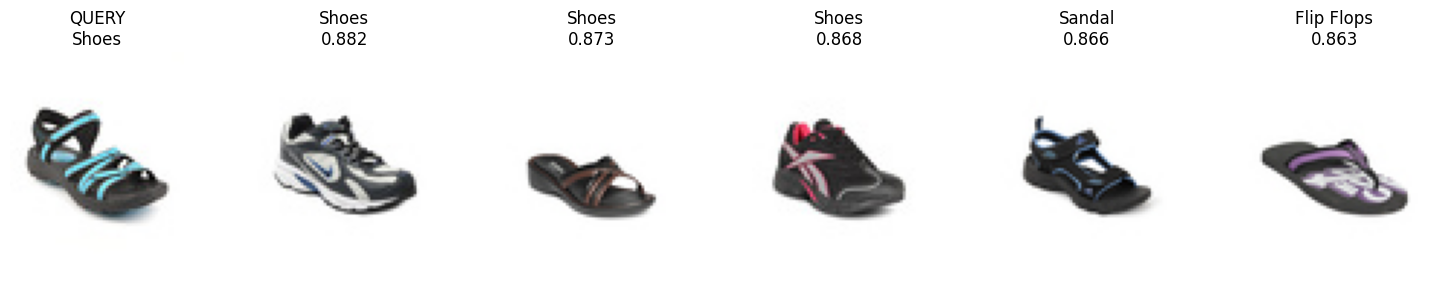

In [16]:
fig, axes = plt.subplots(1, top_k + 1, figsize=(15, 3))
query_row = loaded_metadata.iloc[query_index]
axes[0].imshow(Image.open(PROJECT_DIR / query_row['image_path']))
axes[0].set_title(f"QUERY\n{query_row['category']}")
axes[0].axis('off')

for position, (result_index, score) in enumerate(zip(top_indices, top_scores), start=1):
    result_row = loaded_metadata.iloc[result_index]
    axes[position].imshow(Image.open(PROJECT_DIR / result_row['image_path']))
    axes[position].set_title(f"{result_row['category']}\n{score:.3f}")
    axes[position].axis('off')

plt.tight_layout()
plt.show()

**Interpretation:** Look for shared shape, texture, and category. A different-category result is not always visually unreasonable, and a same-category result is not always a close visual match.

## 15. Simple evaluation with Precision@K

For a query whose known category is *Sneaker*, Precision@5 asks how many of the five retrieved images are also labeled *Sneaker*. This is simple and useful, but not a complete measure of visual quality.

In [17]:
query_category = query_row['category']
retrieved_categories = loaded_metadata.iloc[top_indices]['category']
same_category_matches = (retrieved_categories == query_category).sum()
precision_at_k = same_category_matches / top_k

print('Query category:', query_category)
print('Retrieved categories:', retrieved_categories.tolist())
print(f'Precision@{top_k}: {same_category_matches}/{top_k} = {precision_at_k:.2f}')

Query category: Shoes
Retrieved categories: ['Shoes', 'Shoes', 'Shoes', 'Sandal', 'Flip Flops']
Precision@5: 3/5 = 0.60


## 16. Evaluate several queries

One successful query may be luck. We sample multiple queries, calculate Precision@5 for each, and average the scores. This is still an educational check rather than a production benchmark.

Mean Precision@5 over 100 queries: 0.930


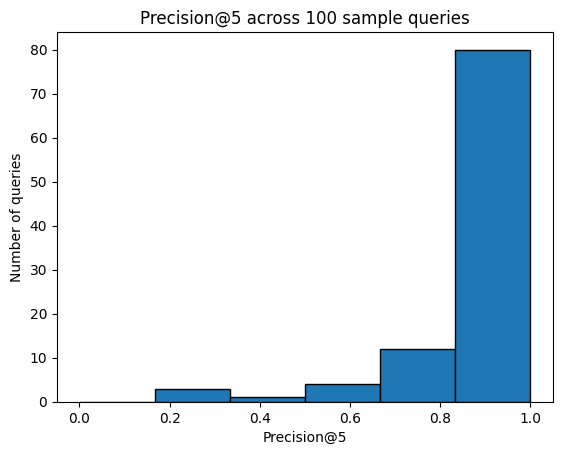

In [18]:
evaluation_indices = loaded_metadata.sample(100, random_state=RANDOM_SEED).index
precision_scores = []

for evaluation_index in evaluation_indices:
    scores = loaded_embeddings @ loaded_embeddings[evaluation_index]
    ranking = np.argsort(scores)[::-1]
    neighbors = ranking[ranking != evaluation_index][:5]

    expected_category = loaded_metadata.iloc[evaluation_index]['category']
    neighbor_categories = loaded_metadata.iloc[neighbors]['category']
    precision_scores.append((neighbor_categories == expected_category).mean())

print(f'Mean Precision@5 over 100 queries: {np.mean(precision_scores):.3f}')
plt.hist(precision_scores, bins=np.linspace(0, 1, 7), edgecolor='black')
plt.title('Precision@5 across 100 sample queries')
plt.xlabel('Precision@5')
plt.ylabel('Number of queries')
plt.show()

**Interpretation:** The average summarizes category consistency, while the histogram shows whether performance is reliable or varies strongly between queries. Categories are only a proxy: visual similarity and label equality are not identical.

## 17. Build reusable functions

Only now—after seeing model inference, normalization, similarity, ranking, and Top-K directly—do we package the steps for reuse in the Streamlit application.

In [19]:
def create_query_embedding(image, model, preprocessing, device):
    image_tensor = preprocessing(image.convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        embedding_tensor = model(image_tensor)
        embedding_tensor = torch.nn.functional.normalize(embedding_tensor, p=2, dim=1)
    return embedding_tensor.cpu().numpy()[0].astype('float32')


def search_top_k(query_embedding, dataset_embeddings, top_k=5, exclude_index=None):
    scores = dataset_embeddings @ query_embedding
    ranked_indices = np.argsort(scores)[::-1]
    if exclude_index is not None:
        ranked_indices = ranked_indices[ranked_indices != exclude_index]
    top_indices = ranked_indices[:top_k]
    return top_indices, scores[top_indices]

In [20]:
def display_search_results(query_image, result_indices, result_scores, metadata):
    number_of_results = len(result_indices)
    fig, axes = plt.subplots(1, number_of_results + 1, figsize=(3 * (number_of_results + 1), 3))
    axes[0].imshow(query_image)
    axes[0].set_title('QUERY')
    axes[0].axis('off')

    for position, (index, score) in enumerate(zip(result_indices, result_scores), start=1):
        row = metadata.iloc[index]
        axes[position].imshow(Image.open(PROJECT_DIR / row['image_path']))
        axes[position].set_title(f"{row['category']}\n{score:.3f}")
        axes[position].axis('off')

    plt.tight_layout()
    plt.show()

## 18. Final notebook demo

Choose any dataset row below. In the Streamlit stage, the query follows the same pipeline but comes from a user upload.

Query ID: 57744
Query category: Makeup


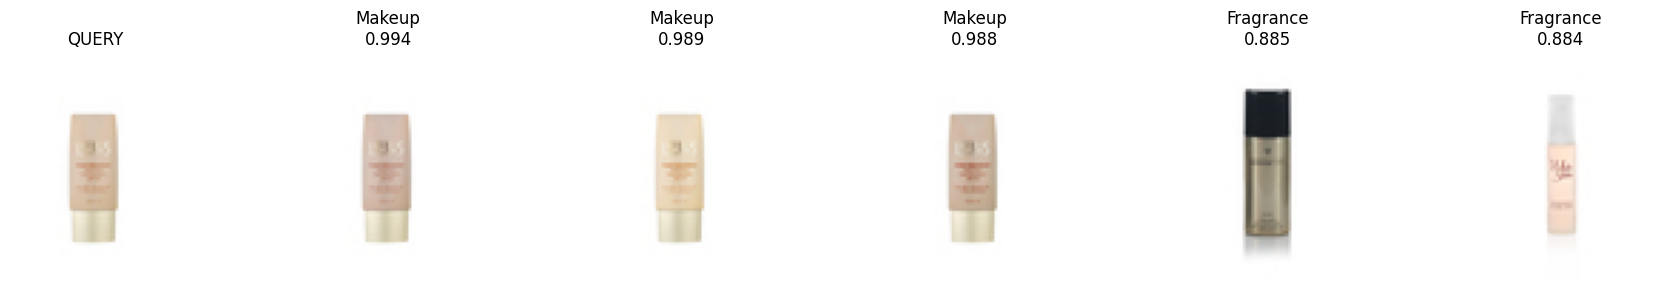

In [21]:
demo_query_index = 123
demo_row = loaded_metadata.iloc[demo_query_index]
demo_image = Image.open(PROJECT_DIR / demo_row['image_path']).convert('RGB')
demo_embedding = create_query_embedding(demo_image, model, preprocessing, device)
demo_indices, demo_scores = search_top_k(
    demo_embedding, loaded_embeddings, top_k=5, exclude_index=demo_query_index
)

print('Query ID:', demo_row['image_id'])
print('Query category:', demo_row['category'])
display_search_results(demo_image, demo_indices, demo_scores, loaded_metadata)

## 19. From notebook to Streamlit

The cleaned Python implementation keeps four responsibilities clear:

- `prepare_dataset.py`: download/export images and create metadata
- `generate_embeddings.py`: run dataset inference once and save `embeddings.npy`
- `search.py`: load the same model, embed one query, and rank cosine similarity
- `app.py`: upload, display, cache, and call the search logic

Streamlit's model cache loads MobileNet once, and its data cache loads embeddings once. Only the uploaded query is processed during a search.

## 20. Final takeaways

1. Pixels are transformed into a learned numerical representation.
2. The same model and preprocessing must be used for catalog and query images.
3. Cosine similarity gives one score per catalog image.
4. Sorting scores produces Top-K retrieval.
5. Saved embeddings make an interactive app practical.
6. Precision@K is a simple category-based evaluation, not a complete judgment of visual quality.
7. Brute-force search is acceptable here; much larger catalogs need specialized indexing, which is outside this beginner project.